# Import Lib


In [33]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier


from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.svm import SVC

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix


from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OneHotEncoder

# 1.Data understanding
* Read Data
* Random Sample Data 
* Size of Data 
* Information of Data
* Check Names of Columns 
* Check Description 

In [34]:
df = pd.read_csv('AB_NYC_2019.csv')

* pd.read_csv() reads a CSV file and loads its data into a Pandas DataFrame.
* AB_NYC_2019.csv is a dataset containing Airbnb listings in New York City in 2019.

In [35]:
df.head(5)

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


**Observation**: The first five rows provide an initial overview of the dataset, including the column names and sample values for each feature.

In [36]:
df.shape

(48895, 16)

**Observation:** The dataset contains 48,895 rows and 16 columns, providing information about Airbnb listings in New York City in 2019.

In [37]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  str    
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     38843 non-n

**Observation:**

The dataset contains 48,895 rows and 16 columns. Each row represents an Airbnb listing in New York City in 2019.

The dataset includes numerical and categorical features describing listing prices, locations, room types, host information, minimum nights, reviews, and availability.

The `price` column is the target variable for the regression task.

The dataset contains three main data types:
- **Integer (`int64`):** 7 columns, representing whole-number values such as `price`, `minimum_nights`, and `number_of_reviews`.
- **Float (`float64`):** 3 columns, representing decimal values such as `latitude`, `longitude`, and `reviews_per_month`.
- **String (`str`):** 6 columns, representing text data such as `name`, `host_name`, and `room_type`.

The `info()` output reveals missing values in four columns:
- **`name`:** 16 missing values.
- **`host_name`:** 21 missing values.
- **`last_review`:** 10,052 missing values.
- **`reviews_per_month`:** 10,052 missing values.

The remaining 12 columns contain no missing values.

These missing values will be investigated during the data-cleaning stage to determine the most appropriate treatment for each column.

In [38]:
df.columns.tolist()

['id',
 'name',
 'host_id',
 'host_name',
 'neighbourhood_group',
 'neighbourhood',
 'latitude',
 'longitude',
 'room_type',
 'price',
 'minimum_nights',
 'number_of_reviews',
 'last_review',
 'reviews_per_month',
 'calculated_host_listings_count',
 'availability_365']

In [39]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


**Observation:**

The descriptive statistics show considerable variation in Airbnb listing prices. The average price is approximately $152.72, while the median price is $106. This difference suggests a right-skewed price distribution, potentially influenced by high-priced listings.

The minimum price is $0, and the maximum price is $10,000. These values require further investigation to identify potential invalid values and outliers before making any treatment decisions.

The `minimum_nights` column has a maximum value of 1,250 nights, which may represent an unusual listing and should be investigated. The `number_of_reviews` column also shows substantial variation, with a maximum of 629 reviews.

The `reviews_per_month` column contains 38,843 non-missing values, indicating that 10,052 values are missing. Finally, the `availability_365` column ranges from 0 to 365 days, showing differences in listing availability.

These findings will guide further data exploration, visualization, and outlier analysis.

# 2.Data Cleaning
* Missing Values 
* Duplicate Rows 
* Outlier Detection
* Outlier Treatment Techniques 

In [40]:
df.isnull().sum()

id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

**Observation**
The missing values analysis reveals that the dataset contains missing values in four columns.

- `name`: 16 missing values .
- `host_name`: 21 missing values .
- `last_review`: 10,052 missing values .
- `reviews_per_month`: 10,052 missing values .

The remaining 12 columns contain no missing values.

In [41]:
df.duplicated().sum()

np.int64(0)

**Observation**

The `df.duplicated().sum()` command returned 0, indicating that the dataset contains no fully duplicated rows. Therefore, no rows need to be removed due to complete duplication at this stage.

## Outlier Detection


In [42]:
cols = ['price', 'minimum_nights', 'number_of_reviews',
        'reviews_per_month', 'calculated_host_listings_count', 'availability_365']


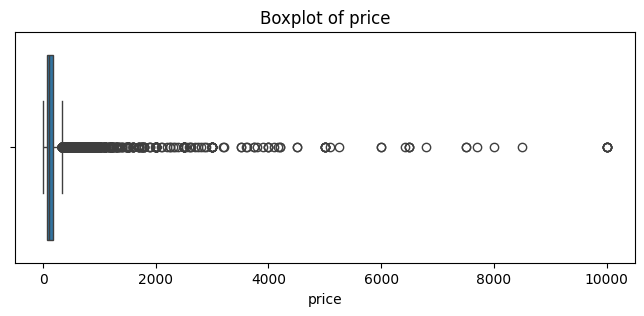

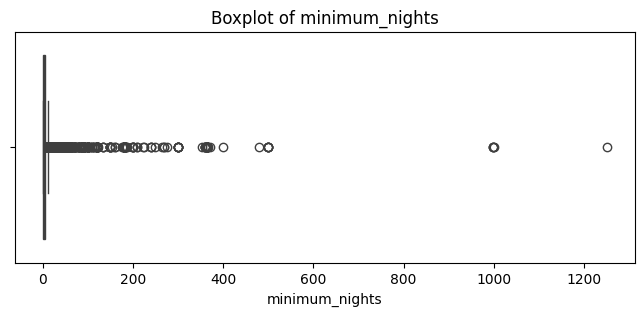

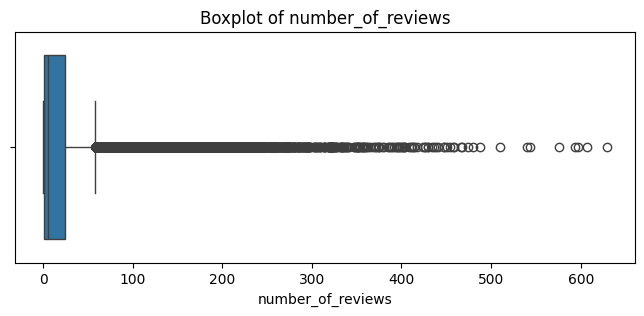

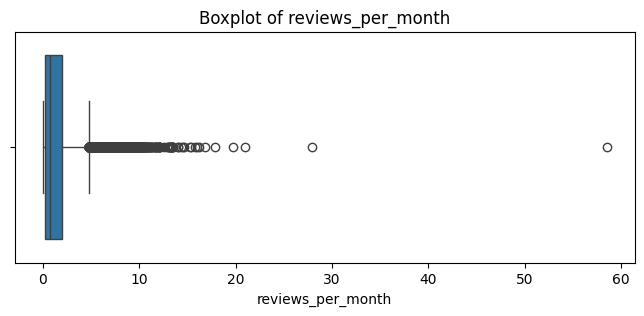

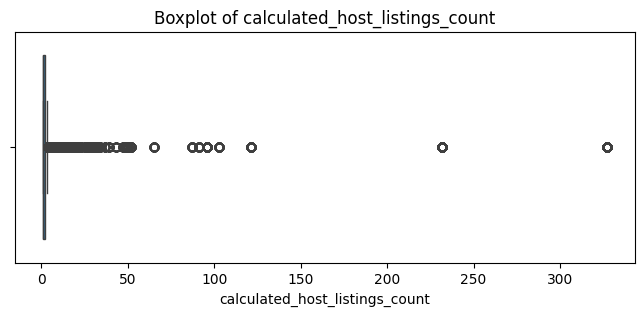

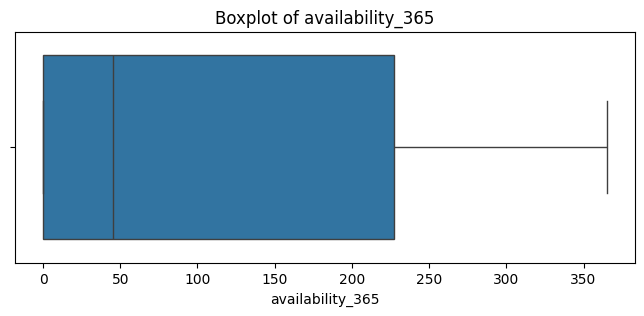

In [43]:
for col in cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

**Observation:**

The boxplots show many points above the upper whisker in `price`, `minimum_nights`, `number_of_reviews`, `reviews_per_month`, and `calculated_host_listings_count`, which suggests the presence of outliers in these columns. In contrast, `availability_365` shows no outliers because its values stay within the range 0 to 365.

In [44]:
summary = df[cols].describe(percentiles=[0.5, 0.95, 0.99]).T
summary[['min', '50%', '95%', '99%', 'max']]

,min,50%,95%,99%,max
price,0.00,106.00,355.00,799.0000,10000.0
minimum_nights,1.00,3.00,30.00,45.0000,1250.0
number_of_reviews,0.00,5.00,114.00,214.0000,629.0
reviews_per_month,0.01,0.72,4.64,7.1958,58.5
calculated_host_listings_count,1.00,1.00,15.00,232.0000,327.0
availability_365,0.00,45.00,359.00,365.0000,365.0


**Observation:**

The summary table shows that the maximum values of `price`, `minimum_nights`, `number_of_reviews`, `reviews_per_month`, and `calculated_host_listings_count` are far above their 99th percentile (for example, the maximum price is 10,000 while the 99th percentile is 799). This confirms the presence of outliers in these columns. `availability_365` has no extreme values because it stays between 0 and 365.

Some values are clearly invalid or unrealistic: 11 listings have price = 0, and 14 listings have minimum_nights above 365. The other extreme values (such as price above 1000) may represent real luxury listings, so they need a careful treatment decision.

In [45]:
print("price = 0:", (df['price'] == 0).sum())
print("price > 1000:", (df['price'] > 1000).sum())
print("minimum_nights > 365:", (df['minimum_nights'] > 365).sum())

price = 0: 11
price > 1000: 239
minimum_nights > 365: 14


# Outlier Treatment

In [46]:

cols = [
    'price',
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month'
]

for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    print(col)
    print("Lower limit:", lower)
    print("Upper limit:", upper)
    print("--------------------")


price
Lower limit: -90.0
Upper limit: 334.0
--------------------
minimum_nights
Lower limit: -5.0
Upper limit: 11.0
--------------------
number_of_reviews
Lower limit: -33.5
Upper limit: 58.5
--------------------
reviews_per_month
Lower limit: -2.555
Upper limit: 4.765000000000001
--------------------


**Observation**
The IQR method was used to identify potential outliers in four numerical columns. The results show that values above the upper limits may be considered outliers. The lower limits are negative for all four columns, although these features represent non-negative values. Therefore, the lower limits do not require treatment, and the focus will be on investigating unusually high values.

In [47]:

for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    upper = Q3 + 1.5 * IQR

    print(col, "Outliers:", (df[col] > upper).sum())


price Outliers: 2972
minimum_nights Outliers: 6607
number_of_reviews Outliers: 6021
reviews_per_month Outliers: 1793


**Observation:**

The IQR method identified potential outliers in four numerical features. The `minimum_nights` column has the highest number of detected outliers (6,607), followed by `number_of_reviews` (6,021), `price` (2,972), and `reviews_per_month` (1,793). These values require further investigation before deciding how to treat them.

In [48]:

df_clean = df.copy()

for col in cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    upper = Q3 + 1.5 * IQR

    df_clean[col] = df_clean[col].clip(upper=upper)


In [49]:

for col in cols:
    print(col)
    print("Maximum before:", df[col].max())
    print("Maximum after:", df_clean[col].max())
    print("--------------------")


price
Maximum before: 10000
Maximum after: 334
--------------------
minimum_nights
Maximum before: 1250
Maximum after: 11
--------------------
number_of_reviews
Maximum before: 629
Maximum after: 58.5
--------------------
reviews_per_month
Maximum before: 58.5
Maximum after: 4.765000000000001
--------------------


**Observation:**

Capping was applied to the four selected numerical columns using their IQR upper limits. The maximum values were reduced from 10,000 to 334 for `price`, from 1,250 to 11 for `minimum_nights`, from 629 to 58.5 for `number_of_reviews`, and from 58.5 to approximately 4.77 for `reviews_per_month`. This reduces the influence of extreme values while preserving the dataset rows.

## Missing Values


In [50]:

print("Missing values before:", df.isnull().sum().sum())
print("Missing values after:", df_clean.isnull().sum().sum())

print("\nDataset shape before:", df.shape)
print("Dataset shape after:", df_clean.shape)


Missing values before: 20141
Missing values after: 20141

Dataset shape before: (48895, 16)
Dataset shape after: (48895, 16)


**Observation:**

The dataset contains 48,895 rows and 16 columns before and after outlier treatment. The total number of missing values remains 20,141, confirming that capping changed extreme values without removing rows or handling missing data.

In [51]:

print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])


name                    16
host_name               21
last_review          10052
reviews_per_month    10052
dtype: int64


**Observation:**

The dataset contains missing values in four columns: `name` (16), `host_name` (21), `last_review` (10,052), and `reviews_per_month` (10,052). The missing values in the text columns are few, while the two review-related columns have substantially more missing values and require appropriate treatment.

In [52]:

print("Rows with 0 reviews:",
      (df_clean['number_of_reviews'] == 0).sum())

print("Missing reviews_per_month with 0 reviews:",
      (df_clean['reviews_per_month'].isnull() &
       (df_clean['number_of_reviews'] == 0)).sum())


Rows with 0 reviews: 10052
Missing reviews_per_month with 0 reviews: 10052


**Observation:**

There are 10,052 listings with zero reviews, and all 10,052 missing values in `reviews_per_month` belong to these listings. Therefore, the missing values can reasonably be replaced with zero because these listings have no recorded reviews.

In [53]:

df_clean['reviews_per_month'] = df_clean['reviews_per_month'].fillna(0)

df_clean['name'] = df_clean['name'].fillna('Unknown')
df_clean['host_name'] = df_clean['host_name'].fillna('Unknown')

df_clean = df_clean.drop(columns=['last_review'])


In [62]:

print("Missing values after treatment:",
      df_clean.isnull().sum().sum())

print("Dataset shape:", df_clean.shape)


Missing values after treatment: 0
Dataset shape: (48895, 15)


**Observation:**

After missing value treatment, the dataset contains zero missing values. The number of rows remains 48,895, while the number of columns decreases from 16 to 15 because the `last_review` column was removed. The dataset is now complete with respect to missing values.

# Exploratory Data Analysis (EDA)

* 1.  Univariate Analysis     
* 2.  Feature vs. Target Analysis
* 3.  Feature-to-Feature Analysis  
* 4.  Correlation Analysis
* 5.  GroupBy / Statistical Summary Analysis Group 

###  1-Univariate Analysis

In [63]:

numerical_cols = df_clean.select_dtypes(include='number').columns

summary = df_clean[numerical_cols].describe().T

summary['median'] = df_clean[numerical_cols].median()
summary['skewness'] = df_clean[numerical_cols].skew()

summary.round(2)


,count,mean,std,min,25%,50%,75%,max,median,skewness
id,48895.0,19017143.24,10983108.39,2539.00,9471945.00,19677284.00,2.915218e+07,3.648724e+07,19677284.00,-0.09
host_id,48895.0,67620010.65,78610967.03,2438.00,7822033.00,30793816.00,1.074344e+08,2.743213e+08,30793816.00,1.21
latitude,48895.0,40.73,0.05,40.50,40.69,40.72,4.076000e+01,4.091000e+01,40.72,0.24
longitude,48895.0,-73.95,0.05,-74.24,-73.98,-73.96,-7.394000e+01,-7.371000e+01,-73.96,1.28
price,48895.0,139.41,102.10,20.00,69.00,106.00,1.750000e+02,5.000000e+02,106.00,1.75
minimum_nights,48895.0,5.95,8.67,1.00,1.00,3.00,5.000000e+00,3.000000e+01,3.00,2.17
number_of_reviews,48895.0,21.47,35.80,0.00,1.00,5.00,2.400000e+01,1.500000e+02,5.00,2.27
reviews_per_month,48895.0,1.06,1.44,0.00,0.04,0.37,1.580000e+00,6.000000e+00,0.37,1.67
calculated_host_listings_count,48895.0,7.14,32.95,1.00,1.00,1.00,2.000000e+00,3.270000e+02,1.00,7.93
availability_365,48895.0,112.78,131.62,0.00,0.00,45.00,2.270000e+02,3.650000e+02,45.00,0.76


**Observation:**

The dataset contains 48,895 records. The average Airbnb price is 139.41, while the median is 106, indicating that prices are generally right-skewed. The `minimum_nights`, `number_of_reviews`, and `reviews_per_month` features also show positive skewness, meaning that most listings have relatively low values while a smaller number have much higher values.

The `calculated_host_listings_count` feature has a highly right-skewed distribution, indicating that most hosts have few listings, while a small number manage many listings. The `latitude` and `longitude` values show relatively low variation, as expected for listings located within New York City. The `id` and `host_id` columns are identifiers rather than meaningful numerical measurements, so their means and standard deviations are not useful for interpreting listing characteristics.

In [64]:
categorical_cols = ['neighbourhood_group', 'room_type']

for col in categorical_cols:
    print(f"\n{col}:")
    print(df_clean[col].value_counts())


neighbourhood_group:
neighbourhood_group
Manhattan        21661
Brooklyn         20104
Queens            5666
Bronx             1091
Staten Island      373
Name: count, dtype: int64

room_type:
room_type
Entire home/apt    25409
Private room       22326
Shared room         1160
Name: count, dtype: int64


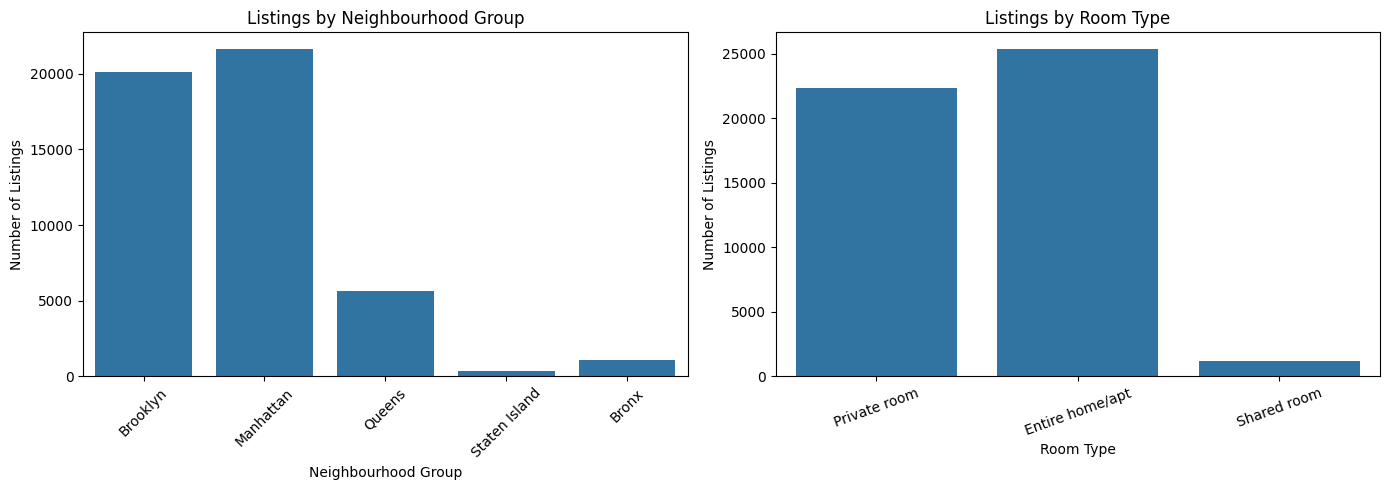

In [66]:


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df_clean, x='neighbourhood_group', ax=axes[0])
axes[0].set_title('Listings by Neighbourhood Group')
axes[0].set_xlabel('Neighbourhood Group')
axes[0].set_ylabel('Number of Listings')
axes[0].tick_params(axis='x', rotation=45)

sns.countplot(data=df_clean, x='room_type', ax=axes[1])
axes[1].set_title('Listings by Room Type')
axes[1].set_xlabel('Room Type')
axes[1].set_ylabel('Number of Listings')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()


###  2-Feature vs. Target Analysis

In [67]:

print("Average Price by Neighbourhood Group:")
print(df_clean.groupby('neighbourhood_group')['price'].mean().round(2))

print("\nAverage Price by Room Type:")
print(df_clean.groupby('room_type')['price'].mean().round(2))


Average Price by Neighbourhood Group:
neighbourhood_group
Bronx             84.45
Brooklyn         117.05
Manhattan        175.27
Queens            94.95
Staten Island     97.74
Name: price, dtype: float64

Average Price by Room Type:
room_type
Entire home/apt    190.99
Private room        84.49
Shared room         66.62
Name: price, dtype: float64


**Observation: Price vs. Neighbourhood Group and Room Type**

The average price varies across neighbourhood groups. Manhattan has the highest average price at 175.27, while the Bronx has the lowest at 84.45. Brooklyn has an average price of 117.05, followed by Staten Island at 97.74 and Queens at 94.95.

Regarding room types, entire home/apartments have the highest average price at 190.99, followed by private rooms at 84.49 and shared rooms at 66.62.

These results suggest that both neighbourhood group and room type are associated with Airbnb prices. The location and type of accommodation may be important features for predicting the price.

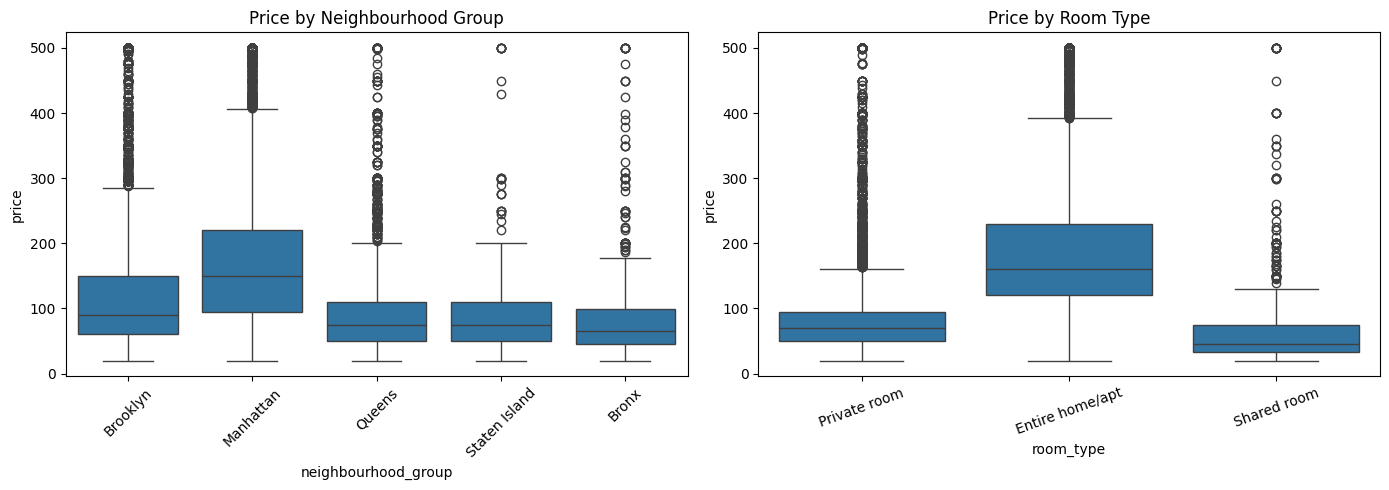

In [68]:


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df_clean, x='neighbourhood_group',
            y='price', ax=axes[0])
axes[0].set_title('Price by Neighbourhood Group')
axes[0].tick_params(axis='x', rotation=45)

sns.boxplot(data=df_clean, x='room_type',
            y='price', ax=axes[1])
axes[1].set_title('Price by Room Type')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()


In [69]:

print("Average Price by Minimum Nights:")
print(df_clean.groupby('minimum_nights')['price'].mean().round(2).head(10))

print("\nAverage Price by Number of Reviews:")
print(df_clean.groupby('number_of_reviews')['price'].mean().round(2).head(10))

print("\nAverage Price by Availability:")
print(df_clean.groupby('availability_365')['price'].mean().round(2).head(10))


Average Price by Minimum Nights:
minimum_nights
1     122.73
2     140.19
3     152.72
4     153.39
5     146.02
6     154.59
7     131.30
8     119.48
9     121.56
10    125.64
Name: price, dtype: float64

Average Price by Number of Reviews:
number_of_reviews
0    160.24
1    136.30
2    134.01
3    137.80
4    136.62
5    142.88
6    139.45
7    136.65
8    138.85
9    138.36
Name: price, dtype: float64

Average Price by Availability:
availability_365
0    126.88
1    128.91
2    141.54
3    136.49
4    133.96
5    133.44
6    123.00
7    132.38
8    128.94
9    145.43
Name: price, dtype: float64


**Observation: Price vs. Numerical Features**

The average Airbnb price varies according to the minimum number of nights. Listings requiring three to six nights generally show higher average prices than listings requiring only one night, although the relationship is not consistent.

The average price also varies with the number of reviews. Listings with zero reviews have an average price of 160.24, which is higher than the average price for listings with one or two reviews. This suggests that the number of reviews alone does not necessarily determine the listing price.

Further visualization is needed to better understand the relationships between price, minimum nights, number of reviews, and availability.

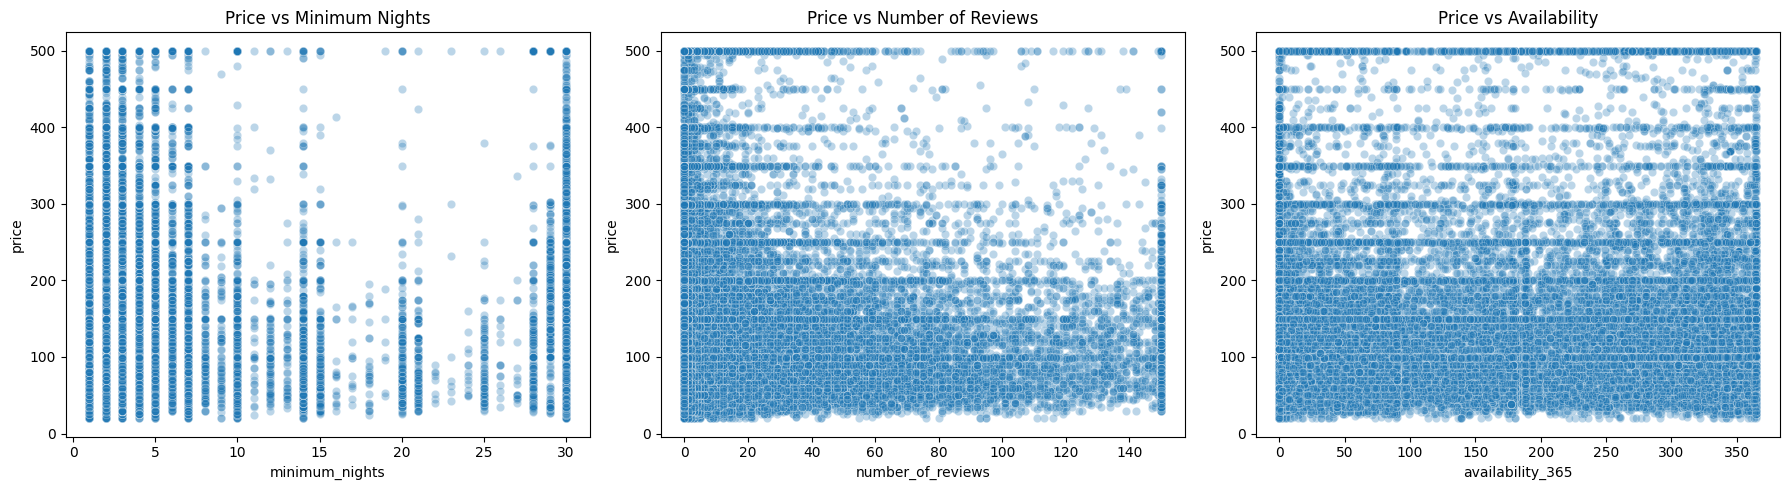

In [70]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=df_clean, x='minimum_nights',
                y='price', alpha=0.3, ax=axes[0])
axes[0].set_title('Price vs Minimum Nights')

sns.scatterplot(data=df_clean, x='number_of_reviews',
                y='price', alpha=0.3, ax=axes[1])
axes[1].set_title('Price vs Number of Reviews')

sns.scatterplot(data=df_clean, x='availability_365',
                y='price', alpha=0.3, ax=axes[2])
axes[2].set_title('Price vs Availability')

plt.tight_layout()
plt.show()


###  3-Feature-to-Feature Analysis

In [71]:

print("Average Number of Reviews by Minimum Nights:")
print(
    df_clean.groupby('minimum_nights')['number_of_reviews']
    .mean().round(2).head(10)
)

print("\nAverage Availability by Room Type:")
print(
    df_clean.groupby('room_type')['availability_365']
    .mean().round(2)
)

print("\nAverage Availability by Neighbourhood Group:")
print(
    df_clean.groupby('neighbourhood_group')['availability_365']
    .mean().round(2)
)


Average Number of Reviews by Minimum Nights:
minimum_nights
1     25.54
2     27.76
3     24.49
4     21.10
5     15.62
6     13.44
7      9.19
8      9.45
9      7.46
10     7.92
Name: number_of_reviews, dtype: float64

Average Availability by Room Type:
room_type
Entire home/apt    111.92
Private room       111.20
Shared room        162.00
Name: availability_365, dtype: float64

Average Availability by Neighbourhood Group:
neighbourhood_group
Bronx            165.76
Brooklyn         100.23
Manhattan        111.98
Queens           144.45
Staten Island    199.68
Name: availability_365, dtype: float64


**Observation: Feature-to-Feature Analysis**

The results show that listings with fewer minimum nights tend to receive more reviews on average. For example, listings requiring one night have an average of 25.54 reviews, while listings requiring seven nights have an average of 9.19 reviews. This suggests a possible relationship between minimum nights and the number of reviews.

Regarding availability, shared rooms have the highest average availability at 162 days per year, compared with 111.92 days for entire homes/apartments and 111.20 days for private rooms.

Among neighbourhood groups, Staten Island has the highest average availability at 199.68 days, while Brooklyn has the lowest at 100.23 days.

These patterns suggest that minimum nights, room type, and neighbourhood group may be related to guest activity and listing availability.

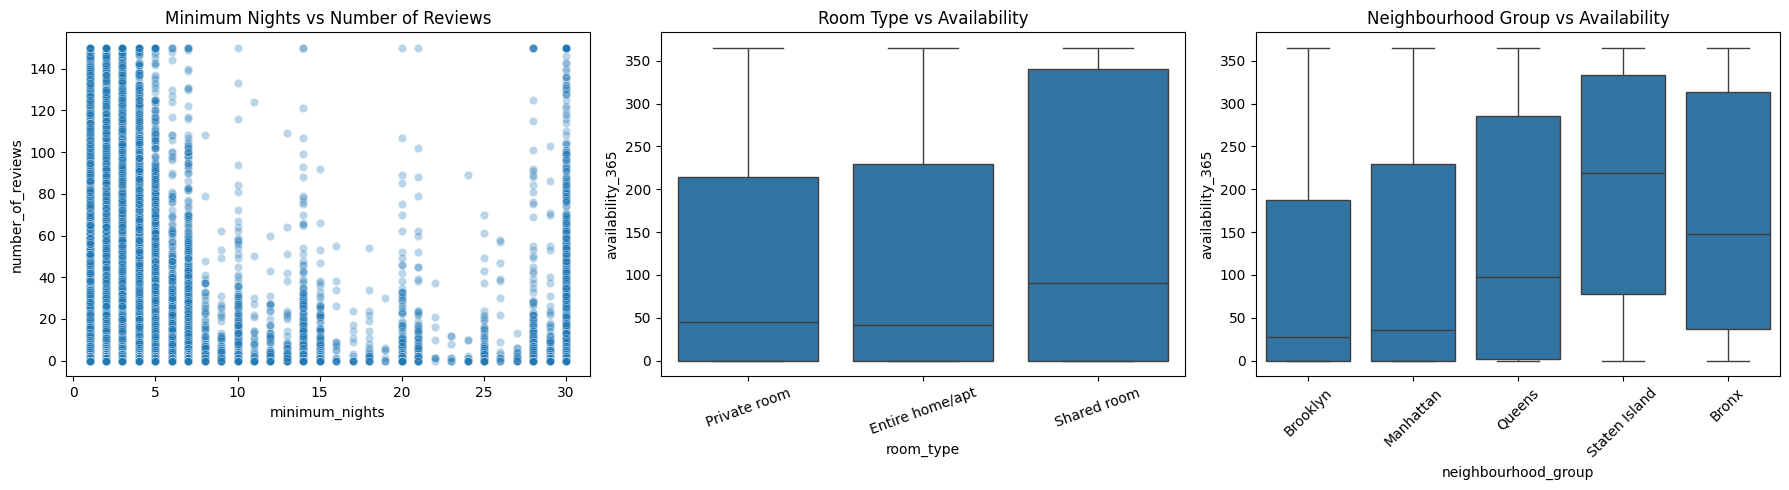

In [72]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(
    data=df_clean, x='minimum_nights',
    y='number_of_reviews', alpha=0.3, ax=axes[0]
)
axes[0].set_title('Minimum Nights vs Number of Reviews')

sns.boxplot(
    data=df_clean, x='room_type',
    y='availability_365', ax=axes[1]
)
axes[1].set_title('Room Type vs Availability')
axes[1].tick_params(axis='x', rotation=20)

sns.boxplot(
    data=df_clean, x='neighbourhood_group',
    y='availability_365', ax=axes[2]
)
axes[2].set_title('Neighbourhood Group vs Availability')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


###  4-Correlation Analysis

In [73]:

numerical_cols = [
    'price',
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month',
    'calculated_host_listings_count',
    'availability_365',
    'latitude',
    'longitude'
]

correlation = df_clean[numerical_cols].corr().round(2)

print("Correlation Matrix:")
print(correlation)


Correlation Matrix:
                                price  minimum_nights  number_of_reviews  \
price                            1.00            0.05              -0.06   
minimum_nights                   0.05            1.00              -0.17   
number_of_reviews               -0.06           -0.17               1.00   
reviews_per_month               -0.06           -0.24               0.64   
calculated_host_listings_count   0.14            0.31              -0.08   
availability_365                 0.12            0.25               0.19   
latitude                         0.07            0.05              -0.02   
longitude                       -0.29           -0.11               0.06   

                                reviews_per_month  \
price                                       -0.06   
minimum_nights                              -0.24   
number_of_reviews                            0.64   
reviews_per_month                            1.00   
calculated_host_listings_count

**Observation: Correlation Analysis**

The correlation matrix shows that most numerical features have weak relationships with price. The strongest correlation with price is longitude, with a negative correlation of -0.29, suggesting that location may be associated with differences in Airbnb prices.

The number of reviews and reviews per month have a positive correlation of 0.64, indicating that listings receiving more reviews overall tend to have higher monthly review activity.

Minimum nights has a negative correlation of -0.24 with reviews per month, suggesting that listings requiring longer stays tend to receive fewer reviews per month.

Overall, most numerical features show weak correlations with one another. These findings suggest that additional features, such as room type and neighbourhood group, may be important for predicting Airbnb prices. Correlation does not necessarily imply causation.

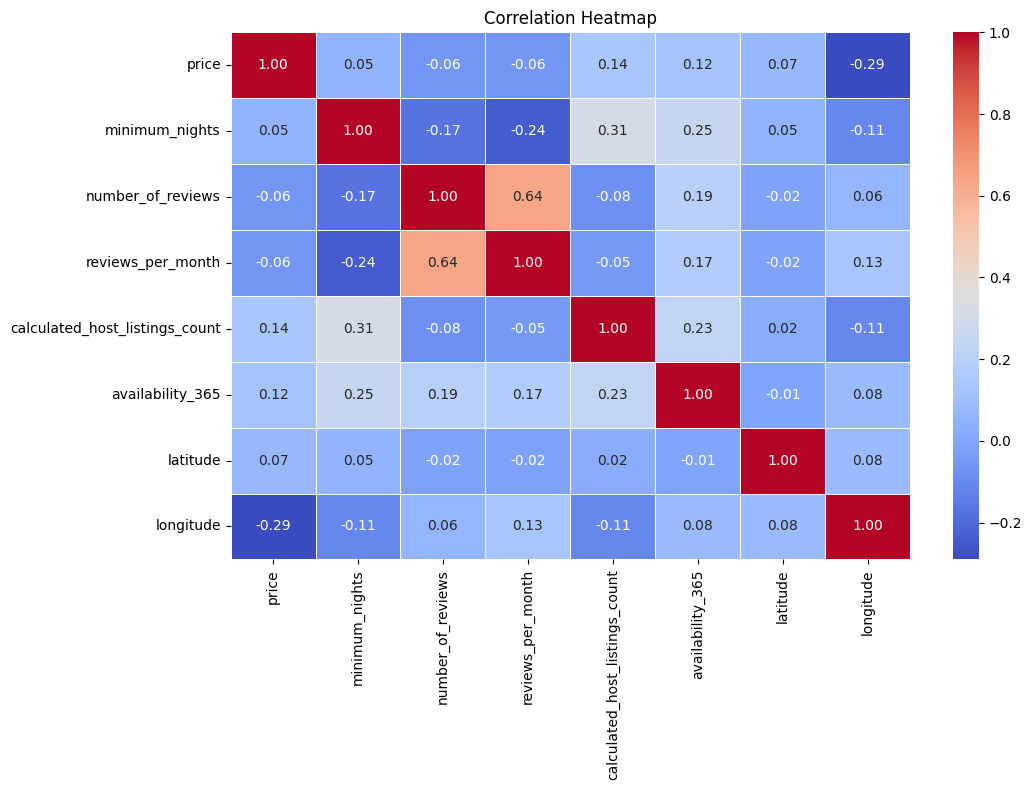

In [74]:

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()


###  5-GroupBy / Statistical Summary Analysis 

In [75]:

print("Statistics by Neighbourhood Group:")
print(
    df_clean.groupby('neighbourhood_group')['price']
    .agg(['count', 'mean', 'median'])
    .round(2)
)

print("\nStatistics by Room Type:")
print(
    df_clean.groupby('room_type')['price']
    .agg(['count', 'mean', 'median'])
    .round(2)
)


Statistics by Neighbourhood Group:
                     count    mean  median
neighbourhood_group                       
Bronx                 1091   84.45    65.0
Brooklyn             20104  117.05    90.0
Manhattan            21661  175.27   150.0
Queens                5666   94.95    75.0
Staten Island          373   97.74    75.0

Statistics by Room Type:
                 count    mean  median
room_type                             
Entire home/apt  25409  190.99   160.0
Private room     22326   84.49    70.0
Shared room       1160   66.62    45.0


**Observation: GroupBy / Statistical Summary Analysis**

The statistical summary shows clear differences in Airbnb prices across neighbourhood groups and room types.

Manhattan has the highest average price (175.27) and median price (150), while the Bronx has the lowest average price (84.45) and median price (65). Brooklyn has the largest number of listings among the neighbourhood groups, with 20,104 listings.

Regarding room types, entire homes/apartments have the highest average price (190.99) and median price (160). Shared rooms have the lowest average price (66.62) and median price (45). Entire homes/apartments also represent the largest number of listings, with 25,409 listings.

These findings show that both neighbourhood group and room type are useful features for understanding Airbnb price differences.

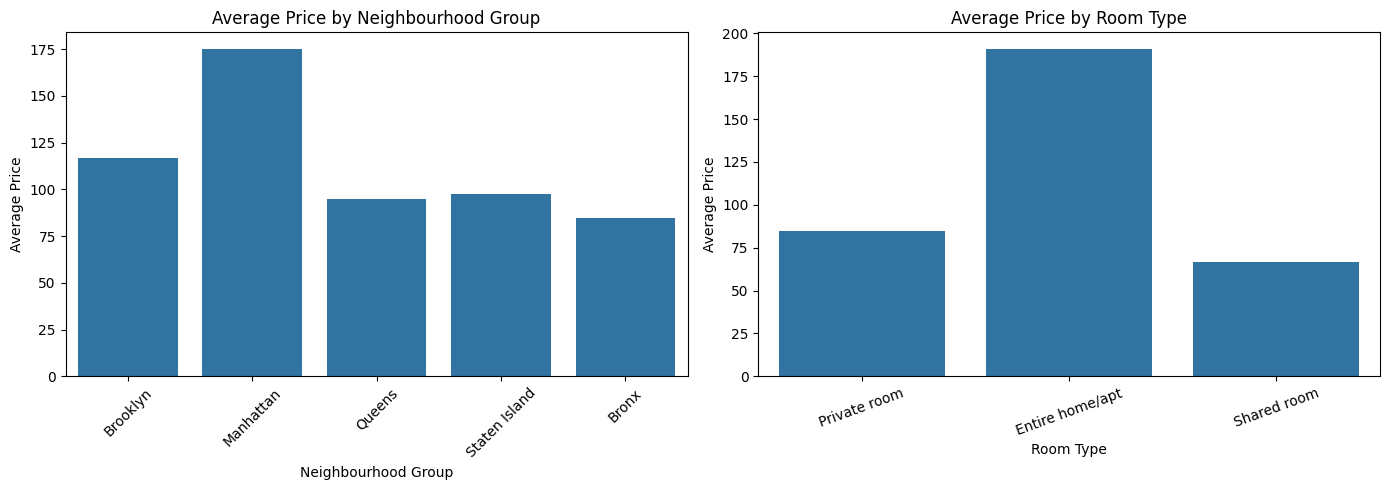

In [76]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=df_clean,
    x='neighbourhood_group',
    y='price',
    ax=axes[0],
    errorbar=None
)
axes[0].set_title('Average Price by Neighbourhood Group')
axes[0].set_xlabel('Neighbourhood Group')
axes[0].set_ylabel('Average Price')
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(
    data=df_clean,
    x='room_type',
    y='price',
    ax=axes[1],
    errorbar=None
)
axes[1].set_title('Average Price by Room Type')
axes[1].set_xlabel('Room Type')
axes[1].set_ylabel('Average Price')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()


In [77]:

print("Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())

print("\nTarget Variable (Price) Summary:")
print(df_clean['price'].describe().round(2))


Dataset Shape: (48895, 15)

Missing Values:
0

Duplicate Rows:
0

Target Variable (Price) Summary:
count    48895.00
mean       139.41
std        102.10
min         20.00
25%         69.00
50%        106.00
75%        175.00
max        500.00
Name: price, dtype: float64


In [78]:

comparison = pd.DataFrame({
    'Original Data': [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum()
    ],
    'Cleaned Data': [
        df_clean.shape[0],
        df_clean.shape[1],
        df_clean.isnull().sum().sum(),
        df_clean.duplicated().sum()
    ]
}, index=[
    'Number of Rows',
    'Number of Columns',
    'Missing Values',
    'Duplicate Rows'
])

print(comparison)


                   Original Data  Cleaned Data
Number of Rows             48895         48895
Number of Columns             16            15
Missing Values             20141             0
Duplicate Rows                 0             0


In [79]:

from IPython.display import display, HTML

original = {
    "Rows": df.shape[0],
    "Columns": df.shape[1],
    "Missing Values": int(df.isnull().sum().sum()),
    "Duplicate Rows": int(df.duplicated().sum())
}

cleaned = {
    "Rows": df_clean.shape[0],
    "Columns": df_clean.shape[1],
    "Missing Values": int(df_clean.isnull().sum().sum()),
    "Duplicate Rows": int(df_clean.duplicated().sum())
}

comparison = pd.DataFrame({
    "Original Dataset": original,
    "Cleaned Dataset": cleaned
})

display(HTML("""
<h2 style="text-align:center; color:#24527a;">
Airbnb Dataset: Before vs After Cleaning
</h2>
<p style="text-align:center; color:#666;">
A summary of the dataset before and after data cleaning
</p>
"""))

display(
    comparison.style
    .set_caption("Dataset Comparison")
    .format("{:,.0f}")
    .background_gradient(cmap="Blues", axis=0)
    .set_properties(**{
        "text-align": "center",
        "padding": "12px",
        "font-size": "14px"
    })
    .set_table_styles([
        {
            "selector": "th",
            "props": [
                ("background-color", "#24527a"),
                ("color", "white"),
                ("text-align", "center"),
                ("padding", "12px")
            ]
        },
        {
            "selector": "caption",
            "props": [
                ("font-size", "18px"),
                ("font-weight", "bold"),
                ("color", "#24527a"),
                ("padding", "10px")
            ]
        }
    ])
)


,Original Dataset,Cleaned Dataset
Rows,"48,895","48,895"
Columns,16,15
Missing Values,"20,141",0
Duplicate Rows,0,0


**Observation: Comparison Between Original and Cleaned Dataset**

The comparison shows that the dataset originally contained 48,895 rows and 16 columns. After data cleaning, the number of rows remained unchanged at 48,895, while the number of columns decreased to 15 because the `last_review` column was removed.

The number of missing values decreased from 20,141 to zero after handling missing data. No duplicate rows were found in either dataset.

Overall, the cleaning process successfully handled the missing values while preserving all records. The dataset is now more suitable for the next stages of data analysis and machine learning.

In [80]:

from IPython.display import display

outlier_cols = [
    'price',
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month'
]

comparison_outliers = pd.DataFrame({
    'Original Mean': df[outlier_cols].mean(),
    'Cleaned Mean': df_clean[outlier_cols].mean(),
    'Original Max': df[outlier_cols].max(),
    'Cleaned Max': df_clean[outlier_cols].max()
}).round(2)

display(
    comparison_outliers.style
    .set_caption("Outlier Treatment: Before vs After")
    .background_gradient(cmap="Blues", axis=0)
    .set_properties(**{
        'text-align': 'center',
        'padding': '10px',
        'font-size': '13px'
    })
    .set_table_styles([
        {
            'selector': 'th',
            'props': [
                ('background-color', '#24527a'),
                ('color', 'white'),
                ('text-align', 'center'),
                ('padding', '10px')
            ]
        },
        {
            'selector': 'caption',
            'props': [
                ('font-size', '17px'),
                ('font-weight', 'bold'),
                ('color', '#24527a'),
                ('padding', '10px')
            ]
        }
    ])
)


,Original Mean,Cleaned Mean,Original Max,Cleaned Max
price,152.720000,139.410000,10000.000000,500.000000
minimum_nights,7.030000,5.950000,1250.000000,30.000000
number_of_reviews,23.270000,21.470000,629.000000,150.000000
reviews_per_month,1.370000,1.060000,58.500000,6.000000


**Observation: Outlier Treatment – Before vs After**

The comparison shows that the maximum values and mean values decreased after outlier treatment across all four numerical features.

For `price`, the maximum value decreased from 10,000 to 500, while the mean decreased from 152.72 to 139.41. For `minimum_nights`, the maximum decreased from 1,250 to 30, and the mean decreased from 7.03 to 5.95.

Similarly, the maximum number of reviews decreased from 629 to 150, while its mean decreased from 23.27 to 21.47. For `reviews_per_month`, the maximum decreased from 58.5 to 6, and the mean decreased from 1.37 to 1.06.

These changes indicate that the treatment reduced the influence of extreme values on the dataset. However, some high values may represent legitimate Airbnb listings, so the chosen thresholds should be reviewed before finalizing the dataset for model training.